# 05 - Classificação com Encoder-Decoder

O encoder usa duas convoluções com max pooling e reduz a imagem de 224x224 para 56x56. O decoder usa duas convoluções transpostas (`Conv2DTranspose`) para voltar a 224x224. Depois disso, um `GlobalAveragePooling2D` e uma `Dense` com softmax fazem a classificação nas 4 classes.

Os dados e a divisão treino/validação são os mesmos do `05_cnn_classification.ipynb`. A avaliação no conjunto de teste está no `06_metrics.ipynb`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, GlobalAveragePooling2D, Dense

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
tf.keras.utils.set_random_seed(0)
print(tf.config.list_physical_devices('GPU'))

I0000 00:00:1795091147.550290   38199 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Carregamento dos dados

In [2]:
splits = pd.read_csv(PROJECT_ROOT / 'data' / 'annotations' / 'splits.csv')
classes = sorted(splits['classe'].unique())
print(classes)

def carregar(conjunto):
    df = splits[splits['conjunto'] == conjunto]
    X, y = [], []
    for _, row in df.iterrows():
        caminho = PROJECT_ROOT / row['caminho'].replace('spectrograms', 'mod_spectograms')
        img = Image.open(caminho).convert('RGB').resize((224, 224))
        X.append(np.array(img) / 255.0)
        y.append(classes.index(row['classe']))
    return np.array(X, dtype='float32'), np.array(y)

X_train, y_train = carregar('treino')
X_val, y_val = carregar('validacao')
print(X_train.shape, X_val.shape)

def plotar_historico(history, titulo):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metrica, nome in zip(axes, ['loss', 'accuracy'], ['Perda', 'Acurácia']):
        ax.plot(history.history[metrica], label='Treinamento')
        ax.plot(history.history['val_' + metrica], label='Validação')
        ax.set_title(f'{titulo} — {nome}')
        ax.set_xlabel('Épocas')
        ax.set_ylabel(metrica)
        ax.legend()
    plt.tight_layout()
    plt.show()

['ICTAL', 'NORMAL', 'POS_ICTAL', 'PRE_ICTAL']
(100, 224, 224, 3) (20, 224, 224, 3)


## Arquitetura

In [3]:
encdec = Sequential([
    Input(shape=(224, 224, 3)),
    # Encoder
    Conv2D(16, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),                                                       # 112x112
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),                                                       # 56x56
    # Decoder
    Conv2DTranspose(32, (3, 3), strides=2, activation='relu', padding='same'),  # 112x112
    Conv2DTranspose(16, (3, 3), strides=2, activation='relu', padding='same'),  # 224x224
    # Classificação
    GlobalAveragePooling2D(),
    Dense(4, activation='softmax'),
])

encdec.summary()

I0000 00:00:1795091151.527744   38199 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5194 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070, pci bus id: 0000:06:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 112, 112, 32)   │         9,248 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 224, 224, 16)   │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,028 (74.33 KB)

 Trainable params: 19,028 (74.33 KB)

 Non-trainable params: 0 (0.00 B)

## Treinamento

In [4]:
encdec.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history_encdec = encdec.fit(X_train, y_train, epochs=30, validation_data=(X_val, y_val), verbose=2)

Epoch 1/30


I0000 00:00:1795091153.274266   38335 service.cc:153] XLA service 0x752948003a90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1795091153.274285   38335 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3070, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.28.1)
I0000 00:00:1795091153.312573   38335 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1795091153.458142   38335 cuda_dnn.cc:461] Loaded cuDNN version 92801
I0000 00:00:1795091153.466750   38335 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1976__.32
I0000 00:00:1795091158.309645   38335 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1795091158.519900   38336 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1976__.32


4/4 - 10s - 2s/step - accuracy: 0.2500 - loss: 1.3862 - val_accuracy: 0.2500 - val_loss: 1.3832
Epoch 2/30
4/4 - 0s - 36ms/step - accuracy: 0.2500 - loss: 1.3855 - val_accuracy: 0.2500 - val_loss: 1.3807
Epoch 3/30
4/4 - 0s - 38ms/step - accuracy: 0.2500 - loss: 1.3849 - val_accuracy: 0.2500 - val_loss: 1.3767
Epoch 4/30
4/4 - 0s - 36ms/step - accuracy: 0.2500 - loss: 1.3840 - val_accuracy: 0.2500 - val_loss: 1.3706
Epoch 5/30
4/4 - 0s - 37ms/step - accuracy: 0.2500 - loss: 1.3828 - val_accuracy: 0.2500 - val_loss: 1.3616
Epoch 6/30
4/4 - 0s - 34ms/step - accuracy: 0.2500 - loss: 1.3813 - val_accuracy: 0.2500 - val_loss: 1.3492
Epoch 7/30
4/4 - 0s - 36ms/step - accuracy: 0.2500 - loss: 1.3797 - val_accuracy: 0.2500 - val_loss: 1.3345
Epoch 8/30
4/4 - 0s - 35ms/step - accuracy: 0.2500 - loss: 1.3790 - val_accuracy: 0.2500 - val_loss: 1.3204
Epoch 9/30
4/4 - 0s - 34ms/step - accuracy: 0.2500 - loss: 1.3800 - val_accuracy: 0.2500 - val_loss: 1.3113
Epoch 10/30
4/4 - 0s - 35ms/step - accur

## Gráficos

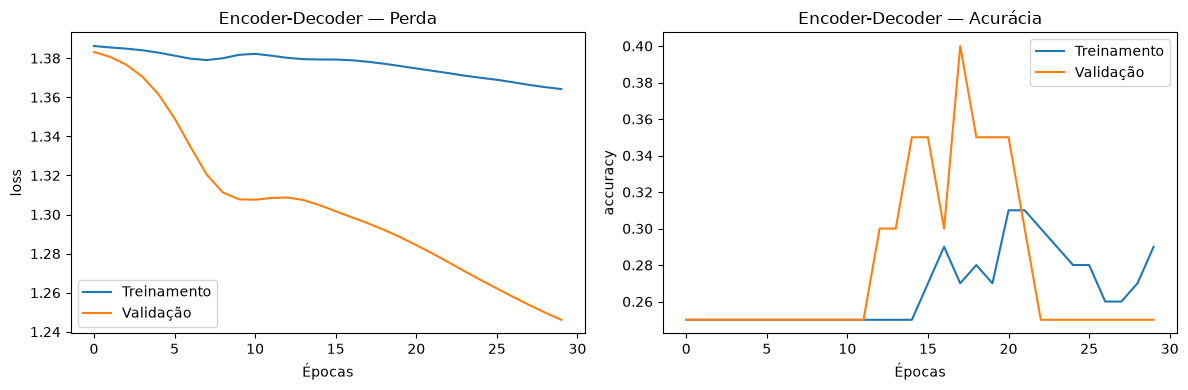

In [5]:
plotar_historico(history_encdec, 'Encoder-Decoder')

## Resultados (Encoder-Decoder)

A rede quase não aprendeu. A loss de treino começa em 1,386 e termina em 1,364, muito perto de ln 4 ≈ 1,386, que é a loss de um modelo que dá 25% para cada classe. A acurácia de treino vai de 25% para 29% (máximo de 31%). Na validação, a acurácia fica entre 25% e 40% e termina em 25%, e a loss de validação cai devagar até 1,25 na última época.

Como as saídas são quase uniformes, uma variação pequena de probabilidade já muda a classe prevista, e por isso a acurácia de validação oscila. Uma causa provável é o `GlobalAveragePooling2D` aplicado nos mapas de 224x224 do decoder: ele tira a média da imagem inteira e perde a informação espacial, e sobra só uma `Dense` de 68 parâmetros para classificar. Como a loss de validação ainda estava caindo, mais épocas podem ajudar.

## Salvando o modelo

In [6]:
encdec.save(PROJECT_ROOT / 'models' / 'modelo_encdec.keras')

## Próximo passo

A avaliação no conjunto de teste está no notebook `06_metrics.ipynb`.